<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-3-Optimization/plain_vs_residual_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 10000
Testing samples: 2000

Training: Plain MLP


Model: "Plain_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151,306 (591.04 KB)

 Trainable params: 151,306 (591.04 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 200,842 (784.54 KB)

 Trainable params: 200,842 (784.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7001 - loss: 0.8282 - val_accuracy: 0.8010 - val_loss: 0.5471
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8136 - loss: 0.5076 - val_accuracy: 0.8280 - val_loss: 0.4800
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8416 - loss: 0.4380 - val_accuracy: 0.8430 - val_loss: 0.4320
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8549 - loss: 0.4027 - val_accuracy: 0.8360 - val_loss: 0.4416
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8661 - loss: 0.3629 - val_accuracy: 0.8330 - val_loss: 0.4579
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8809 - loss: 0.3293 - val_accuracy: 0.8450 - val_loss: 0.4302
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8871 - loss: 0.3076 - val_accuracy: 0.8450 - val_loss: 0.4206
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8930 - loss: 0.2901 - val_accuracy: 0.8420 - val_

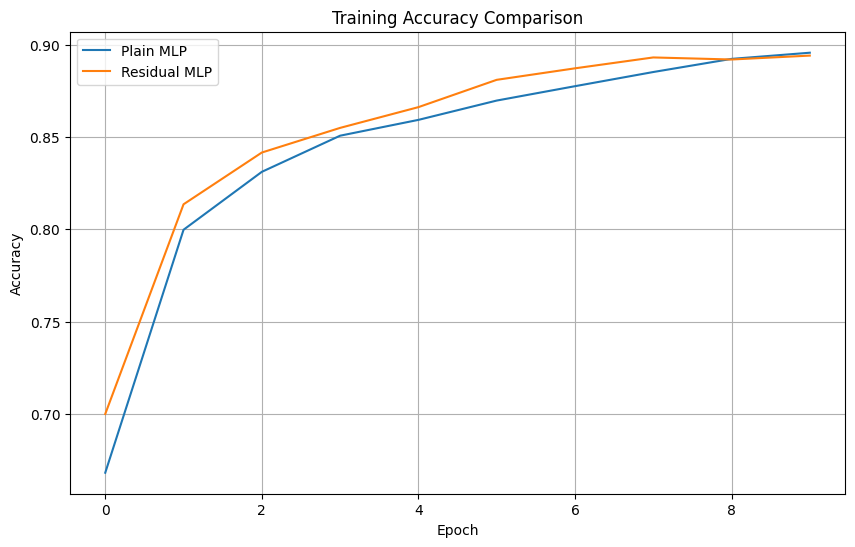

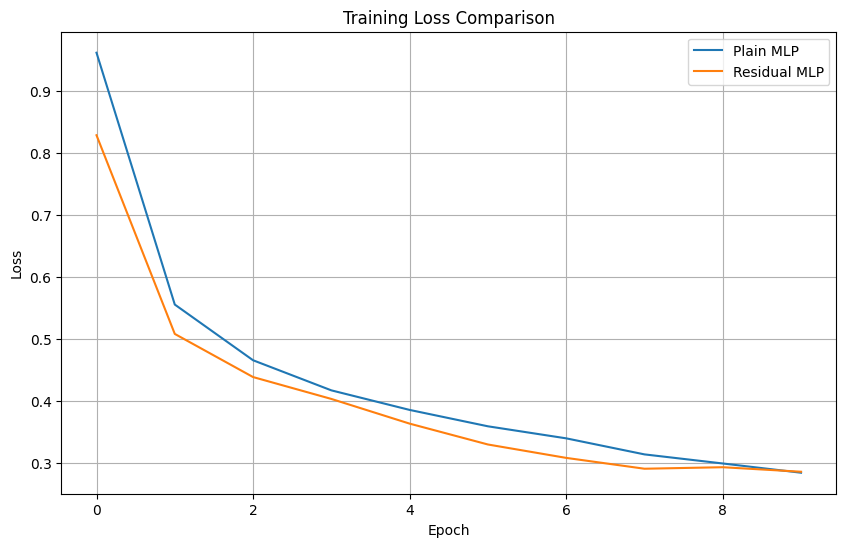

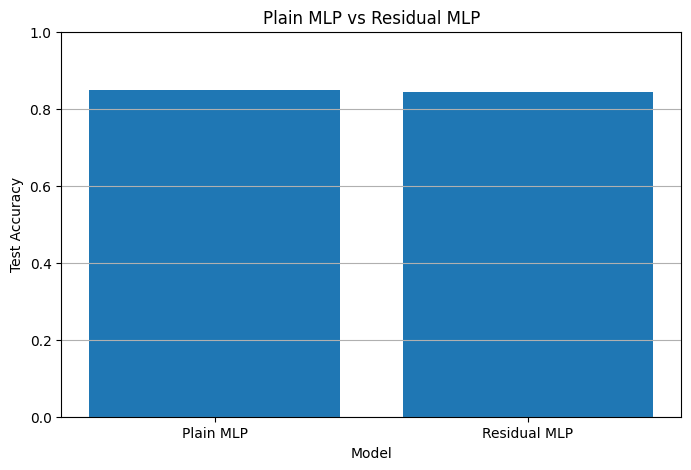

In [1]:
# Assignment 3 - Plain MLP vs Residual MLP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model

# 1. Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Use a smaller subset
X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# 2. Build a Plain MLP
def build_plain_mlp():

    inputs = layers.Input(shape=(28, 28))

    x = layers.Flatten()(inputs)

    x = layers.Dense(128, activation="relu")(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(128, activation="relu")(x)

    outputs = layers.Dense(10, activation="softmax")(x)

    model = Model(inputs, outputs, name="Plain_MLP")

    return model


# 3. Build a Residual MLP
def residual_block(x, units=128):

    shortcut = x

    x = layers.Dense(units, activation="relu")(x)
    x = layers.Dense(units)(x)

    # Add the original input to the block output
    x = layers.Add()([x, shortcut])

    x = layers.Activation("relu")(x)

    return x


def build_residual_mlp():

    inputs = layers.Input(shape=(28, 28))

    x = layers.Flatten()(inputs)

    x = layers.Dense(128, activation="relu")(x)

    # Three residual blocks
    x = residual_block(x)
    x = residual_block(x)
    x = residual_block(x)

    outputs = layers.Dense(10, activation="softmax")(x)

    model = Model(inputs, outputs, name="Residual_MLP")

    return model


# 4. Train and evaluate both models
models = {
    "Plain MLP": build_plain_mlp,
    "Residual MLP": build_residual_mlp
}

histories = {}
results = []

for name, model_function in models.items():

    print("\nTraining:", name)

    tf.keras.utils.set_random_seed(42)

    model = model_function()

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Display model architecture
    model.summary()

    history = model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=128,
        validation_split=0.1,
        verbose=1
    )

    # Evaluate model
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[name] = history.history

    results.append({
        "Model": name,
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    })


# 5. Display comparison
results_df = pd.DataFrame(results)

print("\nPLAIN MLP VS RESIDUAL MLP")
print(results_df.to_string(index=False))


# 6. Compare training accuracy
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["accuracy"], label=name)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 7. Compare training loss
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["loss"], label=name)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# 8. Compare test accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"]
)

plt.title("Plain MLP vs Residual MLP")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()